# Étude de cas : Road Crash : analyse Big Data avec PySpark

Reproduction de l'étude *« Big Data Analysis of Road Crash Data using PySpark with PySpark Tutorial »* (Rakesh Nain, 2021) :
https://medium.com/rakesh-nain/big-data-analysis-of-road-crash-data-using-pyspark-with-pyspark-tutorial-c78ff2c35588

**Données** : accidents de la route en Australie-Méridionale (2012 à 2019), publiés par le *Department of Planning, Transport and Infrastructure* (DPTI), https://data.sa.gov.au.
Deux jeux de données sont utilisés :
- `crash_data/` : un enregistrement par accident (lieu, date, gravité, nombre de victimes, alcool/drogues…) ;
- `units_data/` : un enregistrement par *unité* impliquée (véhicule, piéton…), avec le conducteur (sexe, âge, permis…).

La clé commune est `REPORT_ID`. Le jour exact n'est pas publié : les dates sont affichées au format **Année-Mois-JourDeLaSemaine** (ex. `2017-January-Sunday`).

L'étude est réalisée avec les trois abstractions de Spark :
1. **RDD** (Resilient Distributed Datasets) ;
2. **DataFrames** PySpark ;
3. **Spark SQL**.

Les écarts avec l'article (erreurs corrigées) sont signalés par la mention **Correction**.

## 0. Imports et configuration de Spark

In [1]:
import os
import sys
import csv

from pyspark import SparkConf
from pyspark.sql import SparkSession
from pyspark.rdd import RDD
from pyspark.sql import Window
from pyspark.sql.types import IntegerType
from pyspark.sql.functions import col
import pyspark.sql.functions as F

import pandas as pd
import matplotlib.pyplot as plt

# Les workers Python doivent utiliser le même interpréteur que le driver (le notebook)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Réglages lus au démarrage de la JVM Spark :
# - adresse locale explicite (évite l'avertissement sur le nom d'hôte résolu en 127.0.1.1) ;
# - configuration des logs (log4j2.properties) pour n'afficher que les erreurs dès le démarrage.
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_SUBMIT_ARGS"] = (
    f'--driver-java-options "-Dlog4j.configurationFile=file://{os.path.abspath("log4j2.properties")}" pyspark-shell'
)

On exécute Spark en **mode local** : `local[*]` utilise autant de threads que de cœurs logiques.
Il s'agit donc de *calcul parallèle* (plusieurs cœurs d'une machine) et non de *calcul distribué* (plusieurs machines),
mais le code serait identique sur un cluster : seul le `master` changerait.

In [2]:
master = "local[*]"
app_name = "Big data Analysis of Road Crash Data"
spark_conf = (SparkConf().setMaster(master).setAppName(app_name)
              .set("spark.ui.showConsoleProgress", "false"))   # pas de barre de progression dans les sorties

spark = SparkSession.builder.config(conf=spark_conf).getOrCreate()
sc = spark.sparkContext
sc.setLogLevel("ERROR")
print("Spark", spark.version, "| parallélisme par défaut :", sc.defaultParallelism)

Spark 3.5.9 | parallélisme par défaut : 8


Remarque : sur cette machine, `HADOOP_CONF_DIR` est défini (installation Hadoop du TP précédent), donc un chemin relatif
comme `./crash_data` serait cherché dans **HDFS** (`hdfs://localhost:9000/...`). On utilise donc des chemins `file://` explicites
vers le système de fichiers local.

In [3]:
CRASH_PATH = "file://" + os.path.abspath("crash_data") + "/*.csv"
UNITS_PATH = "file://" + os.path.abspath("units_data") + "/*.csv"
print(CRASH_PATH)
print(UNITS_PATH)

file:///home/ssl/Documents/5A/S9/BD/TP2/crash_data/*.csv
file:///home/ssl/Documents/5A/S9/BD/TP2/units_data/*.csv


## 1. Analyse avec les RDD

Un **RDD** est une collection d'objets immuable, partitionnée et répartie sur les cœurs / nœuds du cluster.
On le manipule avec des **transformations** paresseuses (`map`, `filter`, `groupByKey`…) et des **actions** qui déclenchent le calcul (`collect`, `count`, `take`…).

Deux façons de créer un RDD depuis le `SparkContext` :
- `parallelize()` : à partir d'une collection Python ;
- `textFile()` : à partir de fichiers texte (un élément = une ligne).

In [4]:
data_list = [i for i in range(10)]
rdd = sc.parallelize(data_list)
print("Partitions par défaut :", rdd.getNumPartitions())

rdd = sc.parallelize(data_list, 5)
print("Partitions manuelles  :", rdd.getNumPartitions())
print(rdd.glom().collect())   # contenu de chaque partition

Partitions par défaut : 8
Partitions manuelles  : 5


[[0, 1], [2, 3], [4, 5], [6, 7], [8, 9]]


### 1.1 Chargement des fichiers CSV dans deux RDD

In [5]:
units_rdd = sc.textFile(UNITS_PATH)
crash_rdd = sc.textFile(CRASH_PATH)

# Chaque fichier annuel a la même ligne d'en-tête : un filtre suffit à toutes les retirer
units_header = units_rdd.first()
units_rdd = units_rdd.filter(lambda row: row != units_header)

crash_header = crash_rdd.first()
crash_rdd = crash_rdd.filter(lambda row: row != crash_header)

print("Total count of units_rdd:", units_rdd.count())
for row in units_rdd.take(10):
    print(row)

Total count of units_rdd: 272591
"2012-1-21/08/2019","01",0,,"Pedal Cycle",,"South West","Male","035",,,,,"Straight Ahead","001","5074",,
"2012-1-21/08/2019","02",0,"SA","Motor Cars - Sedan","2009","North West","Female","050","SA","C ","Full","Unknown","Leaving Private Driveway","001","5089",,
"2012-2-21/08/2019","01",0,"SA","Motor Cars - Sedan","1999","West","Male","027","SA",,"Provisional 1 ","Not Towing","Straight Ahead","002","5008",,
"2012-2-21/08/2019","02",0,"SA","Motor Cars - Sedan","1993","West",,,,,,"Not Towing","Parked","000",,,
"2012-3-21/08/2019","01",0,"SA","Motor Cars - Sedan","XXXX","North East","Male","050","SA",,"Full","Trailer","Straight Ahead","006","5107",,
"2012-3-21/08/2019","02",0,"SA","Motor Cars - Sedan","2006","North East","Male","044","SA",,"Full","Not Towing","Straight Ahead","003","5092",,
"2012-3-21/08/2019","03",0,,"Other Inanimate Object",,,,,,,,,,,,,
"2012-4-21/08/2019","01",0,"SA","Station Wagon","2009","South West","Female","037","SA",,"Full","Not To

In [6]:
print("Total count of crash_rdd:", crash_rdd.count())
for row in crash_rdd.take(10):
    print(row)

Total count of crash_rdd: 127672
"2012-1-21/08/2019","2 Metropolitan","STEPNEY","5069","CC OF NORWOOD,PAYNEHAM & ST PETERS",2,0,0,0,0,2012,"January","Sunday","04:30 pm","060","Not Divided","Straight road","Level","Driveway or Entrance","Sealed","Dry","Not Raining","Daylight","Right Angle","02","Driver Rider","1: PDO","No Control","","",1330659.71,1671795.87,"13306601671796"
"2012-2-21/08/2019","2 Metropolitan","PARKSIDE","5063","CITY OF UNLEY",2,0,0,0,0,2012,"January","Sunday","09:10 am","040","Not Divided","Straight road","Level","Not Applicable","Sealed","Dry","Not Raining","Daylight","Hit Parked Vehicle","01","Driver Rider","1: PDO","No Control","","",1329400.16,1668462.66,"13294001668463"
"2012-3-21/08/2019","2 Metropolitan","SELLICKS BEACH","5174","CITY OF ONKAPARINGA",3,0,0,0,0,2012,"January","Wednesday","11:30 am","100","Not Divided","Straight road","Slope","Not Applicable","Sealed","Dry","Not Raining","Daylight","Other","01","Driver Rider","1: PDO","No Control","","",1313748.22

### 1.2 Partitionnement

Sans stratégie explicite, Spark découpe les fichiers en partitions de taille comparable (ici, une par bloc de fichier).

In [7]:
print("Units Data:  total partitions =", units_rdd.getNumPartitions())
print("Crash Data:  total partitions =", crash_rdd.getNumPartitions())

Units Data:  total partitions = 8
Crash Data:  total partitions = 8


#### Découpage des lignes CSV

L'article découpe chaque ligne avec `line.split(',')`. C'est faux dès qu'un champ entre guillemets contient une virgule
(ex. `"Hit Fixed Object, ..."`) : les colonnes sont alors décalées. Vérification :

In [8]:
print("crash, nb de champs avec split(','):", dict(crash_rdd.map(lambda l: len(l.split(','))).countByValue()))
print("crash, nb de champs avec csv.reader :", dict(crash_rdd.map(lambda l: len(next(csv.reader([l])))).countByValue()))
print("units, nb de champs avec split(','):", dict(units_rdd.map(lambda l: len(l.split(','))).countByValue()))

crash, nb de champs avec split(','): {34: 20220, 33: 106293, 35: 924, 36: 235}


crash, nb de champs avec csv.reader : {33: 127672}


units, nb de champs avec split(','): {18: 272591}


Plus de 21 000 accidents seraient mal découpés. On parse donc chaque ligne avec le module `csv` de Python,
et on accède aux colonnes **par leur nom** (via l'en-tête) plutôt que par des indices codés en dur, source d'erreurs dans l'article.

In [9]:
def parse_csv_line(line):
    return next(csv.reader([line]))

U = {name: i for i, name in enumerate(parse_csv_line(units_header))}   # nom de colonne -> indice
C = {name: i for i, name in enumerate(parse_csv_line(crash_header))}

units_fields = units_rdd.map(parse_csv_line).cache()
crash_fields = crash_rdd.map(parse_csv_line).cache()

print("Colonnes Units :", list(U))
print("Colonnes Crash :", list(C))

Colonnes Units : ['REPORT_ID', 'Unit No', 'No Of Cas', 'Veh Reg State', 'Unit Type', 'Veh Year', 'Direction Of Travel', 'Sex', 'Age', 'Lic State', 'Licence Class', 'Licence Type', 'Towing', 'Unit Movement', 'Number Occupants', 'Postcode', 'Rollover', 'Fire']
Colonnes Crash : ['REPORT_ID', 'Stats Area', 'Suburb', 'Postcode', 'LGA Name', 'Total Units', 'Total Cas', 'Total Fats', 'Total SI', 'Total MI', 'Year', 'Month', 'Day', 'Time', 'Area Speed', 'Position Type', 'Horizontal Align', 'Vertical Align', 'Other Feat', 'Road Surface', 'Moisture Cond', 'Weather Cond', 'DayNight', 'Crash Type', 'Unit Resp', 'Entity Code', 'CSEF Severity', 'Traffic Ctrls', 'DUI Involved', 'Drugs Involved', 'ACCLOC_X', 'ACCLOC_Y', 'UNIQUE_LOC']


#### Partitionnement personnalisé

On crée un RDD clé-valeur dont la clé est l'**État d'immatriculation du véhicule** (`Veh Reg State`), puis on le partitionne en deux :
partition 0 pour les véhicules immatriculés en Australie-Méridionale (`SA`), partition 1 pour tous les autres.

(L'article parle de la colonne `Lic State`, mais l'indice 3 qu'il utilise correspond en réalité à `Veh Reg State`, ce qui est cohérent avec « véhicule immatriculé en SA ».)

In [10]:
units_state_rdd = units_fields.map(
    lambda f: (f[U["Veh Reg State"]], [x for i, x in enumerate(f) if i != U["Veh Reg State"]])
)

def hash_SA(key):
    return 0 if key == "SA" else 1

SA_partitioned_rdd = units_state_rdd.partitionBy(2, hash_SA)

def print_partitions(data):
    rdd = data if isinstance(data, RDD) else data.rdd
    print(f"NUMBER OF PARTITIONS: {rdd.getNumPartitions()}")
    # glom().map(len) : on ne rapatrie que la taille de chaque partition, pas son contenu
    for index, size in enumerate(rdd.glom().map(len).collect()):
        if size > 0:
            print(f"Partition {index}: {size} records")

print_partitions(SA_partitioned_rdd)

NUMBER OF PARTITIONS: 2


Partition 0: 218366 records
Partition 1: 54225 records


### 1.3 Requêtes avec les RDD

**Âge moyen des conducteurs, par sexe.** On écarte les âges inconnus (`XXX`, vide) et le sexe `Unknown`.

In [11]:
def parse_gender_age(f):
    sex, age = f[U["Sex"]], f[U["Age"]]
    if age not in ("XXX", "") and sex not in ("Unknown", ""):
        return (sex, int(age))

gender_age_rdd = units_fields.map(parse_gender_age).filter(lambda x: x is not None)

# (somme, effectif) par clé avec aggregateByKey : évite de matérialiser toutes les valeurs comme groupByKey
gender_age_avg_rdd = (gender_age_rdd
                      .aggregateByKey((0, 0),
                                      lambda acc, age: (acc[0] + age, acc[1] + 1),
                                      lambda a, b: (a[0] + b[0], a[1] + b[1]))
                      .mapValues(lambda s: round(s[0] / s[1], 2)))
gender_age_avg_rdd.collect()

[('Male', 40.8), ('Female', 40.08)]

L'âge moyen des hommes et des femmes impliqués dans un accident est quasiment identique (~40 ans), comme dans l'article.

**État d'immatriculation et type des véhicules les plus anciens et les plus récents impliqués dans un accident.**

L'article fait `sortByKey().collect()[0:5]`, ce qui rapatrie tout le RDD sur le driver. `takeOrdered(5)` donne le même résultat
en ne remontant que 5 éléments par partition.

In [12]:
def parse_year(f):
    year = f[U["Veh Year"]]
    if year not in ("XXXX", ""):
        return (int(year), [f[U["Veh Reg State"]], f[U["Unit Type"]]])

clean_year_rdd = units_fields.map(parse_year).filter(lambda x: x is not None)

print("Oldest year 5 crashes:\n", clean_year_rdd.takeOrdered(5, key=lambda x: x[0]))
print("\nNewest year 5 crashes:\n", clean_year_rdd.takeOrdered(5, key=lambda x: -x[0]))

Oldest year 5 crashes:
 [(1900, ['VIC', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle'])]

Newest year 5 crashes:
 [(2019, ['SA', 'Station Wagon']), (2019, ['SA', 'OMNIBUS']), (2019, ['SA', 'Motor Cars - Sedan']), (2019, ['SA', 'Station Wagon']), (2019, ['SA', 'SEMI TRAILER'])]


L'année 1900 est vraisemblablement une valeur par défaut saisie quand l'année du véhicule est inconnue (valeur aberrante).

## 2. Analyse avec les DataFrames

Un **DataFrame** est une collection distribuée organisée en colonnes nommées, comme une table relationnelle.
Contrairement aux RDD, Spark connaît le schéma et optimise les requêtes (optimiseur *Catalyst*).

In [13]:
df = spark.createDataFrame([(1,'Aaditya','A'),(2,'Chinnavit','C'),(3,'Neha','N'),(4,'Huashun','H'),(5,'Mohammad','M'),
                            (10,'Prajwol','P'),(1,'Paras','P'),(1,'Tooba','T'),(3,'David','D'),(4,'Cheng','C'),(9,'Haqqani','H')],
                           ['Id','Name','Initial'])
df.show(5)
df.printSchema()

+---+---------+-------+
| Id|     Name|Initial|
+---+---------+-------+
|  1|  Aaditya|      A|
|  2|Chinnavit|      C|
|  3|     Neha|      N|
|  4|  Huashun|      H|
|  5| Mohammad|      M|
+---+---------+-------+
only showing top 5 rows

root
 |-- Id: long (nullable = true)
 |-- Name: string (nullable = true)
 |-- Initial: string (nullable = true)



### 2.1 Chargement des données

L'option `escape='"'` gère correctement les guillemets dans les champs. Toutes les colonnes sont lues comme des chaînes ;
on convertit en entiers les colonnes numériques utilisées dans les calculs.

In [14]:
units_df = (spark.read.format("csv")
            .option("header", True).option("escape", '"')
            .load(UNITS_PATH))
crash_df = (spark.read.format("csv")
            .option("header", True).option("escape", '"')
            .load(CRASH_PATH))

for c in ["Total Units", "Total Cas", "Total Fats", "Total SI", "Total MI", "Year"]:
    crash_df = crash_df.withColumn(c, col(c).cast(IntegerType()))
for c in ["No Of Cas", "Age", "Veh Year"]:
    units_df = units_df.withColumn(c, col(c).cast(IntegerType()))   # 'XXX' / 'XXXX' -> null

crash_df = crash_df.cache()
units_df = units_df.cache()
print("crash_df :", crash_df.count(), "lignes |", "units_df :", units_df.count(), "lignes")
crash_df.printSchema()

crash_df : 127672 lignes | units_df : 272591 lignes
root
 |-- REPORT_ID: string (nullable = true)
 |-- Stats Area: string (nullable = true)
 |-- Suburb: string (nullable = true)
 |-- Postcode: string (nullable = true)
 |-- LGA Name: string (nullable = true)
 |-- Total Units: integer (nullable = true)
 |-- Total Cas: integer (nullable = true)
 |-- Total Fats: integer (nullable = true)
 |-- Total SI: integer (nullable = true)
 |-- Total MI: integer (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Month: string (nullable = true)
 |-- Day: string (nullable = true)
 |-- Time: string (nullable = true)
 |-- Area Speed: string (nullable = true)
 |-- Position Type: string (nullable = true)
 |-- Horizontal Align: string (nullable = true)
 |-- Vertical Align: string (nullable = true)
 |-- Other Feat: string (nullable = true)
 |-- Road Surface: string (nullable = true)
 |-- Moisture Cond: string (nullable = true)
 |-- Weather Cond: string (nullable = true)
 |-- DayNight: string (nullabl

### 2.2 Requêtes avec les DataFrames

**1. Accidents à Adélaïde avec plus de 3 victimes.**

In [15]:
adelaide_crash_casualty_df = crash_df.filter((col("Total Cas") > 3) & (col("Suburb") == "ADELAIDE"))
print("Nombre d'accidents :", adelaide_crash_casualty_df.count())
adelaide_crash_casualty_df.select("REPORT_ID", "Year", "Month", "Day", "Time", "Crash Type", "Total Cas", "Total Fats").show(truncate=False)

Nombre d'accidents : 6


+---------------------+----+--------+--------+--------+--------------+---------+----------+
|REPORT_ID            |Year|Month   |Day     |Time    |Crash Type    |Total Cas|Total Fats|
+---------------------+----+--------+--------+--------+--------------+---------+----------+
|2012-4842-21/08/2019 |2012|March   |Thursday|04:00 pm|Rear End      |4        |0         |
|2012-5769-21/08/2019 |2012|March   |Friday  |09:30 am|Right Angle   |4        |0         |
|2018-601-17/01/2020  |2018|January |Sunday  |09:12 pm|Hit Pedestrian|4        |0         |
|2017-1613-15/08/2019 |2017|February|Saturday|04:00 pm|Right Turn    |4        |0         |
|2017-12182-15/08/2019|2017|December|Saturday|04:08 pm|Hit Pedestrian|5        |0         |
|2019-10404-8/07/2020 |2019|October |Monday  |08:20 am|Right Turn    |6        |0         |
+---------------------+----+--------+--------+--------+--------------+---------+----------+



**2. Les 10 accidents avec le plus de victimes.**

In [16]:
(crash_df.sort(col("Total Cas"), ascending=False)
 .select("REPORT_ID", "Suburb", "Year", "Month", "Day", "Crash Type", "Total Units", "Total Cas", "Total Fats")
 .show(10, truncate=False))

+---------------------+-------------+----+--------+---------+-----------+-----------+---------+----------+
|REPORT_ID            |Suburb       |Year|Month   |Day      |Crash Type |Total Units|Total Cas|Total Fats|
+---------------------+-------------+----+--------+---------+-----------+-----------+---------+----------+
|2017-288-15/08/2019  |PARA HILLS   |2017|January |Wednesday|Right Angle|2          |11       |0         |
|2014-9004-21/08/2019 |APY          |2014|July    |Friday   |Roll Over  |2          |9        |1         |
|2019-11734-8/07/2020 |STURT        |2019|November|Sunday   |Right Turn |2          |9        |0         |
|2014-14065-21/08/2019|MODBURY NORTH|2014|November|Tuesday  |Rear End   |5          |9        |0         |
|2016-3035-15/08/2019 |HACKHAM      |2016|January |Saturday |Right Turn |3          |9        |3         |
|2016-6630-15/08/2019 |KANGAROO FLAT|2016|April   |Wednesday|Head On    |3          |9        |0         |
|2012-890-21/08/2019  |KULPARA      |

**3. Nombre total de morts par type d'accident.**

In [17]:
(crash_df.groupBy("Crash Type")
 .agg(F.sum("Total Fats").alias("Total fatalities"))
 .sort(col("Total fatalities"), ascending=False)
 .show(truncate=False))

+--------------------------+----------------+
|Crash Type                |Total fatalities|
+--------------------------+----------------+
|Hit Fixed Object          |245             |
|Head On                   |136             |
|Hit Pedestrian            |109             |
|Roll Over                 |93              |
|Right Angle               |82              |
|Rear End                  |33              |
|Side Swipe                |30              |
|Right Turn                |26              |
|Hit Parked Vehicle        |10              |
|Hit Animal                |7               |
|Other                     |5               |
|Left Road - Out of Control|3               |
|Hit Object on Road        |2               |
+--------------------------+----------------+



Les collisions contre un obstacle fixe et les collisions frontales sont de loin les plus mortelles.

**4. Nombre total de victimes par quartier quand le véhicule était conduit par un conducteur sans permis.**

On joint les deux DataFrames sur `REPORT_ID` (une ligne par unité impliquée).

In [18]:
complete_df = crash_df.join(units_df, on="REPORT_ID", how="inner")

by_suburb_no_lic_df = (complete_df.filter(col("Licence Type") == "Unlicenced")
                       .groupBy("Suburb")
                       .agg(F.sum("Total Cas").alias("Total casualty")))
by_suburb_no_lic_df.sort(col("Total casualty"), ascending=False).show()

+---------------+--------------+
|         Suburb|Total casualty|
+---------------+--------------+
|       ADELAIDE|            43|
|      SALISBURY|            30|
|       PROSPECT|            27|
|     INGLE FARM|            22|
| SALISBURY EAST|            20|
|  MORPHETT VALE|            20|
|  MURRAY BRIDGE|            19|
|      DRY CREEK|            19|
| NORTH ADELAIDE|            17|
|   MAWSON LAKES|            17|
|        ENFIELD|            16|
|    GEPPS CROSS|            15|
|   REGENCY PARK|            15|
|SALISBURY DOWNS|            15|
|PARA HILLS WEST|            14|
|         SEATON|            14|
| ELIZABETH PARK|            14|
|   BEDFORD PARK|            13|
|   DAVOREN PARK|            13|
|  MOUNT GAMBIER|            13|
+---------------+--------------+
only showing top 20 rows



**Correction :** `Total Cas` est une donnée **de l'accident**, répétée sur chaque unité après la jointure : si un accident implique deux conducteurs
sans permis, ses victimes sont comptées deux fois (c'est le calcul de l'article). Version sans double comptage, en ne gardant qu'une ligne par accident :

In [19]:
by_suburb_no_lic_dedup_df = (complete_df.filter(col("Licence Type") == "Unlicenced")
                             .dropDuplicates(["REPORT_ID"])
                             .groupBy("Suburb")
                             .agg(F.sum("Total Cas").alias("Total casualty")))
by_suburb_no_lic_dedup_df.sort(col("Total casualty"), ascending=False).show()

+---------------+--------------+
|         Suburb|Total casualty|
+---------------+--------------+
|       ADELAIDE|            42|
|      SALISBURY|            30|
|       PROSPECT|            27|
|     INGLE FARM|            22|
|  MORPHETT VALE|            20|
| SALISBURY EAST|            19|
|  MURRAY BRIDGE|            19|
|      DRY CREEK|            19|
| NORTH ADELAIDE|            17|
|   MAWSON LAKES|            17|
|        ENFIELD|            16|
|    GEPPS CROSS|            15|
|   REGENCY PARK|            15|
|SALISBURY DOWNS|            15|
|PARA HILLS WEST|            14|
| ELIZABETH PARK|            14|
|         SEATON|            14|
|   BEDFORD PARK|            13|
|   DAVOREN PARK|            13|
|  MOUNT GAMBIER|            13|
+---------------+--------------+
only showing top 20 rows



### 2.3 Gravité des accidents, alcool et drogues

La colonne `CSEF Severity` donne la gravité de l'accident (voir les métadonnées) :
- `1: PDO` : *Property Damage Only* (dégâts matériels uniquement) ;
- `2: MI` : *Minor Injury* (blessures légères) ;
- `3: SI` : *Serious Injury* (blessures graves) ;
- `4: Fatal` : accident mortel.

`DUI Involved` et `Drugs Involved` valent `Y` si un conducteur a été contrôlé positif à l'alcool / aux drogues, et sont vides sinon.

**Nombre d'accidents par niveau de gravité :**

In [20]:
severe_df = crash_df.groupBy("CSEF Severity").agg(F.count("REPORT_ID").alias("Total accidents"))
severe_df.sort("CSEF Severity").show()

+-------------+---------------+
|CSEF Severity|Total accidents|
+-------------+---------------+
|       1: PDO|          84775|
|        2: MI|          37300|
|        3: SI|           4875|
|     4: Fatal|            722|
+-------------+---------------+



**Nombre d'accidents et pourcentage par gravité, pour quatre scénarios.**

L'article réécrit le même code quatre fois avec une UDF Python et une variable globale pour le total.
On factorise ici dans une fonction, et le pourcentage est calculé avec une **fenêtre** Spark (`Window`) :
le calcul reste entièrement dans Spark (pas d'aller-retour entre la JVM et Python comme avec une UDF).

In [21]:
def severity_share(filtered_df):
    total = Window.partitionBy()   # fenêtre sur toutes les lignes du résultat (4 lignes : une par gravité)
    return (filtered_df.groupBy("CSEF Severity")
            .agg(F.count("REPORT_ID").alias("Total accidents"))
            .withColumn("percent_share",
                        F.round(col("Total accidents") / F.sum("Total accidents").over(total) * 100, 2))
            .sort("CSEF Severity"))

on_drugs   = col("Drugs Involved") == "Y"
on_alcohol = col("DUI Involved") == "Y"
on_none    = col("Drugs Involved").isNull() & col("DUI Involved").isNull()

a) Conducteur positif aux drogues :

In [22]:
severity_share(crash_df.filter(on_drugs)).show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|       1: PDO|            237|        12.78|
|        2: MI|           1109|        59.82|
|        3: SI|            391|        21.09|
|     4: Fatal|            117|         6.31|
+-------------+---------------+-------------+



b) Conducteur positif à l'alcool :

In [23]:
severity_share(crash_df.filter(on_alcohol)).show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|       1: PDO|           2144|        53.88|
|        2: MI|           1243|        31.24|
|        3: SI|            456|        11.46|
|     4: Fatal|            136|         3.42|
+-------------+---------------+-------------+



c) Conducteur positif à l'alcool **et** aux drogues :

In [24]:
severity_share(crash_df.filter(on_drugs & on_alcohol)).show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|       1: PDO|             36|        12.08|
|        2: MI|            151|        50.67|
|        3: SI|             72|        24.16|
|     4: Fatal|             39|        13.09|
+-------------+---------------+-------------+



d) Conducteur négatif aux deux :

In [25]:
severity_share(crash_df.filter(on_none)).show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|       1: PDO|          82430|        67.49|
|        2: MI|          35099|        28.74|
|        3: SI|           4100|         3.36|
|     4: Fatal|            508|         0.42|
+-------------+---------------+-------------+



**Synthèse des quatre scénarios et visualisation.**

On joint les quatre résultats en une seule table. Pour tracer avec matplotlib, il faut convertir en DataFrame pandas (`toPandas()`),
qui n'est **pas** distribué : tout est rapatrié en mémoire sur le driver. C'est sans risque ici car la table agrégée ne fait que 4 lignes ;
sur une table volumineuse, il faudrait d'abord agréger ou échantillonner.

In [26]:
scenarios = {
    "On Drugs":   crash_df.filter(on_drugs),
    "On Alcohol": crash_df.filter(on_alcohol),
    "On Both":    crash_df.filter(on_drugs & on_alcohol),
    "On None":    crash_df.filter(on_none),
}

def combine(value_col):
    dfs = [severity_share(d).select("CSEF Severity", col(value_col).alias(name)) for name, d in scenarios.items()]
    out = dfs[0]
    for d in dfs[1:]:
        out = out.join(d, on="CSEF Severity")
    return out.sort("CSEF Severity")

all_df = combine("Total accidents")
all_df_per = combine("percent_share")
all_df.show()
all_df_per.show()

pd_df = all_df.toPandas()
pd_df_per = all_df_per.toPandas()

+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|       1: PDO|     237|      2144|     36|  82430|
|        2: MI|    1109|      1243|    151|  35099|
|        3: SI|     391|       456|     72|   4100|
|     4: Fatal|     117|       136|     39|    508|
+-------------+--------+----------+-------+-------+



+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|       1: PDO|   12.78|     53.88|  12.08|  67.49|
|        2: MI|   59.82|     31.24|  50.67|  28.74|
|        3: SI|   21.09|     11.46|  24.16|   3.36|
|     4: Fatal|    6.31|      3.42|  13.09|   0.42|
+-------------+--------+----------+-------+-------+



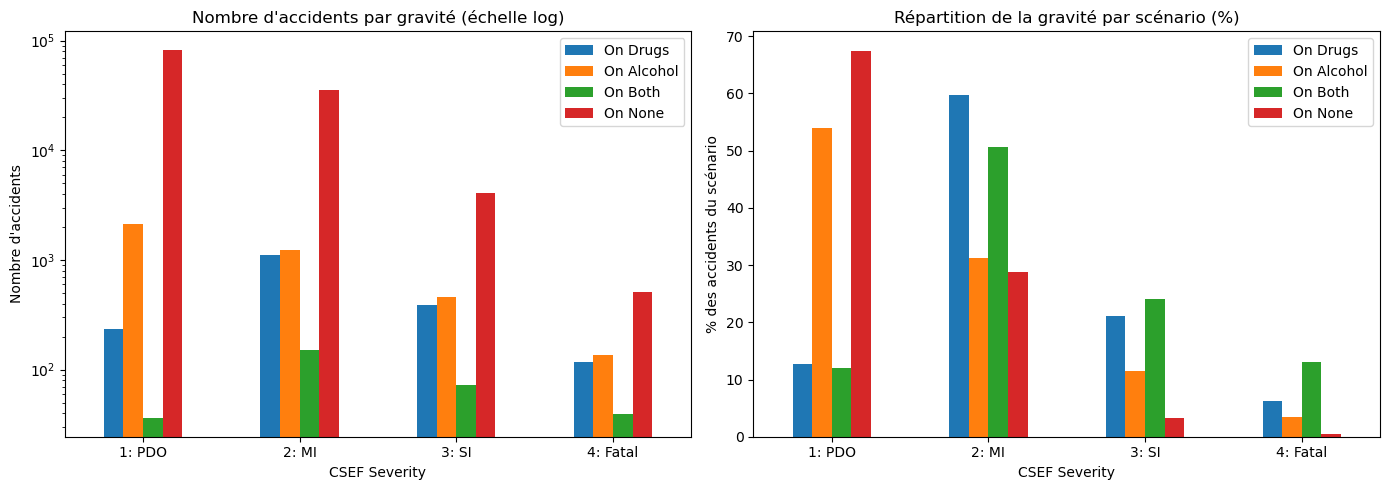

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pd_df.plot(kind="bar", x="CSEF Severity", ax=axes[0], logy=True, rot=0)
axes[0].set_title("Nombre d'accidents par gravité (échelle log)")
axes[0].set_ylabel("Nombre d'accidents")

pd_df_per.plot(kind="bar", x="CSEF Severity", ax=axes[1], rot=0)
axes[1].set_title("Répartition de la gravité par scénario (%)")
axes[1].set_ylabel("% des accidents du scénario")

plt.tight_layout()
plt.savefig("severe.png", dpi=120)
plt.show()

Le graphique des effectifs est en échelle logarithmique : sans cela, le scénario « On None » (~122 000 accidents) écraserait les autres.

**Interprétation.** Sans alcool ni drogues, 67 % des accidents ne causent que des dégâts matériels et 0,4 % sont mortels.
Dès qu'un conducteur est positif, la répartition se décale fortement vers les accidents graves :
- positif à l'alcool : 3,4 % d'accidents mortels (8 fois plus) ;
- positif aux drogues : 6,3 % d'accidents mortels (15 fois plus) et 21 % de blessés graves ;
- positif aux deux : 13 % d'accidents mortels (31 fois plus).

Attention : c'est une **corrélation**. Le dépistage, notamment de drogues, est plus systématique après un accident grave,
ce qui tend à gonfler la part d'accidents graves parmi les cas positifs.

## 3. Même requête avec RDD, DataFrame et Spark SQL

Les trois API permettent d'exprimer les mêmes requêtes. Les DataFrames et Spark SQL passent par le même optimiseur et
produisent le même plan d'exécution ; les RDD laissent le contrôle total, mais sans optimisation automatique.

### 3.1 Date, heure, nombre de victimes, sexe, âge et type de permis du conducteur pour le quartier « ADELAIDE »

**Correction :** Dans la version RDD de l'article, les indices utilisés ne correspondent pas aux colonnes annoncées
(le « nombre de victimes » est en fait `Total Fats`, et les colonnes « sexe, âge, type de permis » sont en fait `Age`, `Lic State` et `Towing`), en plus du problème de `split(',')`.
L'accès par nom de colonne règle ces deux problèmes. La date respecte le format imposé `Année-Mois-JourDeLaSemaine`.

In [28]:
# --- RDD
crash_kv = crash_fields.map(lambda f: (f[C["REPORT_ID"]], f))
units_kv = units_fields.map(lambda f: (f[U["REPORT_ID"]], f))

def adelaide_record(kv):
    unit, crash = kv[1]
    return (f'{crash[C["Year"]]}-{crash[C["Month"]]}-{crash[C["Day"]]}', crash[C["Time"]], int(crash[C["Total Cas"]]),
            unit[U["Sex"]], unit[U["Age"]], unit[U["Licence Type"]], crash[C["Suburb"]])

adelaide_rdd = (units_kv.join(crash_kv)
                .filter(lambda kv: kv[1][1][C["Suburb"]] == "ADELAIDE")
                .map(adelaide_record))
print("RDD :", adelaide_rdd.count(), "lignes")
adelaide_rdd.take(5)

RDD : 11965 lignes


[('2012-April-Friday',
  '02:10 pm',
  0,
  'Female',
  '018',
  'Provisional 1 ',
  'ADELAIDE'),
 ('2012-April-Friday', '02:10 pm', 0, 'Unknown', 'XXX', '', 'ADELAIDE'),
 ('2012-May-Friday', '05:00 pm', 0, 'Male', '027', 'Full', 'ADELAIDE'),
 ('2012-May-Friday', '05:00 pm', 0, 'Male', '031', 'Full', 'ADELAIDE'),
 ('2012-June-Friday', '08:00 pm', 0, 'Female', '025', 'Full', 'ADELAIDE')]

In [29]:
# --- DataFrame
adelaide_df = (crash_df.filter(col("Suburb") == "ADELAIDE")
               .join(units_df, on="REPORT_ID", how="inner")
               .withColumn("Date", F.concat_ws("-", "Year", "Month", "Day"))
               .select("Date", "Time", "Total Cas", "Sex", "Age", "Licence Type", "Suburb"))
print("DataFrame :", adelaide_df.count(), "lignes")
adelaide_df.show(5)

DataFrame : 11965 lignes


+-------------------+--------+---------+----+----+------------+--------+
|               Date|    Time|Total Cas| Sex| Age|Licence Type|  Suburb|
+-------------------+--------+---------+----+----+------------+--------+
|2012-January-Monday|08:45 am|        0|Male|  40|        Full|ADELAIDE|
|2012-January-Monday|08:45 am|        0|Male|  84|        Full|ADELAIDE|
|2012-January-Friday|05:45 pm|        0|Male|NULL|        NULL|ADELAIDE|
|2012-January-Friday|05:45 pm|        0|Male|  47|        Full|ADELAIDE|
|2012-January-Friday|07:30 pm|        1|Male|  20|        Full|ADELAIDE|
+-------------------+--------+---------+----+----+------------+--------+
only showing top 5 rows



In [30]:
# --- Spark SQL
units_df.createOrReplaceTempView("units_table")
crash_df.createOrReplaceTempView("crash_table")

adelaide_sql = spark.sql('''
    SELECT concat_ws('-', c.Year, c.Month, c.Day) AS Date, c.Time, c.`Total Cas`,
           u.Sex, u.Age, u.`Licence Type`, c.Suburb
    FROM units_table u JOIN crash_table c ON u.REPORT_ID = c.REPORT_ID
    WHERE c.Suburb = 'ADELAIDE'
''')
print("Spark SQL :", adelaide_sql.count(), "lignes")
adelaide_sql.show(5)

Spark SQL : 11965 lignes
+-------------------+--------+---------+------+----+-------------+--------+
|               Date|    Time|Total Cas|   Sex| Age| Licence Type|  Suburb|
+-------------------+--------+---------+------+----+-------------+--------+
|2012-January-Monday|08:45 am|        0|  Male|  84|         Full|ADELAIDE|
|2012-January-Monday|08:45 am|        0|  Male|  40|         Full|ADELAIDE|
|2012-January-Friday|05:45 pm|        0|  Male|  47|         Full|ADELAIDE|
|2012-January-Friday|05:45 pm|        0|  Male|NULL|         NULL|ADELAIDE|
|2012-January-Friday|07:30 pm|        1|Female|  18|Provisional 2|ADELAIDE|
+-------------------+--------+---------+------+----+-------------+--------+
only showing top 5 rows



Les trois implémentations renvoient le même nombre de lignes. On peut comparer les plans d'exécution DataFrame et SQL :

In [31]:
adelaide_df.explain()
adelaide_sql.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [concat_ws(-, cast(Year#326 as string), Month#100, Day#101) AS Date#26524, Time#102, Total Cas#190, Sex#43, Age#380, Licence Type#47, Suburb#91]
   +- BroadcastHashJoin [REPORT_ID#89], [REPORT_ID#36], Inner, BuildLeft, false
      :- BroadcastExchange HashedRelationBroadcastMode(List(input[0, string, false]),false), [plan_id=6720]
      :  +- Filter ((isnotnull(Suburb#91) AND (Suburb#91 = ADELAIDE)) AND isnotnull(REPORT_ID#89))
      :     +- InMemoryTableScan [REPORT_ID#89, Suburb#91, Total Cas#190, Year#326, Month#100, Day#101, Time#102], [isnotnull(Suburb#91), (Suburb#91 = ADELAIDE), isnotnull(REPORT_ID#89)]
      :           +- InMemoryRelation [REPORT_ID#89, Stats Area#90, Suburb#91, Postcode#92, LGA Name#93, Total Units#155, Total Cas#190, Total Fats#224, Total SI#258, Total MI#292, Year#326, Month#100, Day#101, Time#102, Area Speed#103, Position Type#104, Horizontal Align#105, Vertical Align#106, Other Feat#107, 

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [concat_ws(-, cast(Year#326 as string), Month#100, Day#101) AS Date#29084, Time#102, Total Cas#190, Sex#43, Age#380, Licence Type#47, Suburb#91]
   +- BroadcastHashJoin [REPORT_ID#36], [REPORT_ID#89], Inner, BuildRight, false
      :- Filter isnotnull(REPORT_ID#36)
      :  +- InMemoryTableScan [REPORT_ID#36, Sex#43, Age#380, Licence Type#47], [isnotnull(REPORT_ID#36)]
      :        +- InMemoryRelation [REPORT_ID#36, Unit No#37, No Of Cas#360, Veh Reg State#39, Unit Type#40, Veh Year#399, Direction Of Travel#42, Sex#43, Age#380, Lic State#45, Licence Class#46, Licence Type#47, Towing#48, Unit Movement#49, Number Occupants#50, Postcode#51, Rollover#52, Fire#53], StorageLevel(disk, memory, deserialized, 1 replicas)
      :              +- *(1) Project [REPORT_ID#36, Unit No#37, cast(No Of Cas#38 as int) AS No Of Cas#360, Veh Reg State#39, Unit Type#40, cast(Veh Year#41 as int) AS Veh Year#399, Direction Of Travel#42, Sex

### 3.2 Nombre total de victimes par quartier pour les conducteurs sans permis

**Correction :** Dans cette partie, les trois versions de l'article ne répondent pas à la question : elles **gardent les conducteurs dont le permis est connu**
(`Licence Type != 'Unknown'`…) au lieu de `Licence Type = 'Unlicenced'`, et utilisent `COUNT` au lieu de `SUM` sur le nombre de victimes.
On implémente ici la question posée, de façon cohérente avec la requête 4 de la partie 2.

In [32]:
# --- RDD
no_lic_rdd = (units_kv.join(crash_kv)
              .filter(lambda kv: kv[1][0][U["Licence Type"]] == "Unlicenced")
              .map(lambda kv: (kv[1][1][C["Suburb"]], int(kv[1][1][C["Total Cas"]])))
              .reduceByKey(lambda a, b: a + b))
no_lic_rdd.takeOrdered(10, key=lambda x: -x[1])

[('ADELAIDE', 43),
 ('SALISBURY', 30),
 ('PROSPECT', 27),
 ('INGLE FARM', 22),
 ('MORPHETT VALE', 20),
 ('SALISBURY EAST', 20),
 ('DRY CREEK', 19),
 ('MURRAY BRIDGE', 19),
 ('NORTH ADELAIDE', 17),
 ('MAWSON LAKES', 17)]

In [33]:
# --- DataFrame
no_lic_df = (crash_df.join(units_df, on="REPORT_ID", how="inner")
             .filter(col("Licence Type") == "Unlicenced")
             .groupBy("Suburb")
             .agg(F.sum("Total Cas").alias("Total casualty"))
             .sort(col("Total casualty").desc(), col("Suburb")))
no_lic_df.show(10)

+--------------+--------------+
|        Suburb|Total casualty|
+--------------+--------------+
|      ADELAIDE|            43|
|     SALISBURY|            30|
|      PROSPECT|            27|
|    INGLE FARM|            22|
| MORPHETT VALE|            20|
|SALISBURY EAST|            20|
|     DRY CREEK|            19|
| MURRAY BRIDGE|            19|
|  MAWSON LAKES|            17|
|NORTH ADELAIDE|            17|
+--------------+--------------+
only showing top 10 rows



In [34]:
# --- Spark SQL
no_lic_sql = spark.sql('''
    SELECT c.Suburb, SUM(c.`Total Cas`) AS `Total casualty`
    FROM units_table u JOIN crash_table c ON u.REPORT_ID = c.REPORT_ID
    WHERE u.`Licence Type` = 'Unlicenced'
    GROUP BY c.Suburb
    ORDER BY `Total casualty` DESC, c.Suburb
''')
no_lic_sql.show(10)

+--------------+--------------+
|        Suburb|Total casualty|
+--------------+--------------+
|      ADELAIDE|            43|
|     SALISBURY|            30|
|      PROSPECT|            27|
|    INGLE FARM|            22|
| MORPHETT VALE|            20|
|SALISBURY EAST|            20|
|     DRY CREEK|            19|
| MURRAY BRIDGE|            19|
|  MAWSON LAKES|            17|
|NORTH ADELAIDE|            17|
+--------------+--------------+
only showing top 10 rows



In [35]:
# Vérification : les trois implémentations donnent exactement le même résultat
rdd_res = set(no_lic_rdd.collect())
df_res = {(r["Suburb"], r["Total casualty"]) for r in no_lic_df.collect()}
sql_res = {(r["Suburb"], r["Total casualty"]) for r in no_lic_sql.collect()}
print("RDD == DataFrame == SQL :", rdd_res == df_res == sql_res, f"({len(rdd_res)} quartiers)")

RDD == DataFrame == SQL : True (752 quartiers)


## Conclusion

- Spark permet de traiter les ~400 000 enregistrements (127 672 accidents, 272 591 unités) en parallèle avec trois API :
  les **RDD**, bas niveau et flexibles mais sans schéma ni optimisation ; les **DataFrames** et **Spark SQL**, plus concis et optimisés par Catalyst.
- Le **partitionnement** peut être personnalisé (`partitionBy` avec une fonction de hachage), par exemple pour séparer les véhicules immatriculés en SA (218 366) des autres (54 225).
- Résultats principaux : âge moyen des conducteurs ~40 ans quel que soit le sexe ; les collisions contre un obstacle fixe et frontales sont les plus mortelles ;
  la part d'accidents mortels est multipliée par ~8 avec l'alcool, ~15 avec les drogues et ~31 avec les deux.
- Corrections apportées à l'article : parsing CSV robuste pour les RDD (le `split(',')` décalait les colonnes de plus de 21 000 accidents),
  accès aux colonnes par nom, requête « sans permis » de la partie 3 qui ne répondait pas à la question, double comptage des victimes après jointure,
  UDF remplacées par des fonctions natives Spark.

In [36]:
spark.stop()